# IBMGO · Genişletilmiş iterasyon ve ölçek deneyleri

250, 500, 1000 ve 5000 testte IBMGO bütçe duyarlılığı. Ana dayanıklılık arşivi ve yöntem karşılaştırması ayrı kayıtlardır. Bu notebook tamamlanmış kayıtları okur.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, HTML, Markdown
from kod.raporlama.iterasyon_birlesik import show_group, show_convergence, show_effects
from kod.raporlama.ek_deney_raporu import load_records

ROOT = Path.cwd()
BIRLESIK = ROOT / "sonuclar/iterasyon_birlesik_180_2026-11-13"
YENI = ROOT / "sonuclar/ek_iterasyon_1000_5000_2026-11-13"
OLCEK = ROOT / "sonuclar/ek_olcek_2026-11-13"
birlesik_manifest = json.loads((BIRLESIK / "manifest.json").read_text(encoding="utf-8"))
yeni_manifest = json.loads((YENI / "manifest.json").read_text(encoding="utf-8"))
assert birlesik_manifest["compatible"] and birlesik_manifest["status"] == "complete"
assert yeni_manifest["status"] == "complete"
olcek, olcek_manifest = load_records(OLCEK)
display(HTML('<p style="padding:14px;background:#edf5f7;color:#172c43;font:16px Segoe UI">'
             f'<b>{birlesik_manifest["completed"]} uyumlu IBMGO koşumu</b> · '
             f'{yeni_manifest["completed"]}/{yeni_manifest["total"]} yeni koşum · '
             'Önceki yöntem karşılaştırması ayrı bölümde</p>'))
def slayt(folder, name):
    display(Image(filename=str(folder / "sunum" / name), width=1100))

## 1 · İterasyon özeti

Her büyüklük ve iterasyon ayarında 3 veri tohumu × 5 başlangıç = 15 koşum var. Popülasyon 12, iterasyon başına yerel deneme 12. Ayarlar 20, 50 ve 100 iterasyon.

Toplam iterasyon hareket katsayılarını ve bit değiştirme takvimini de etkiler. Bu çalışma **farklı toplam arama bütçeleri ve bunlara bağlı kontrol takvimlerini** karşılaştırır. İlk 20 adımın aynı olduğu varsayılmaz.

Tahmini tasarruf sentetik test sürelerinden hesaplanır. Arama süresi bu bilgisayarda, gerçek iz kaydı açıkken ölçülmüştür.

In [2]:
show_group(BIRLESIK, "01_iterasyon_ozet")

### Büyüklük ve veri tohumu bazında yakınsama

Her çizgi aynı veri ve büyüklükte beş başlangıcın ortalaması, bant minimum–maksimum aralığıdır. Bant güven aralığı değildir. X ekseni gerçek fitness değerlendirmesidir. Biten koşum ileri uzatılmaz, yumuşatma uygulanmaz.

In [3]:
show_convergence(BIRLESIK)

### Ek fayda ve hesaplama maliyeti

**Δ amaç puanı = önceki fitness − yeni fitness.** Pozitif değer iyileşmedir. **Δ tasarruf = yeni − önceki tasarruf** ve birimi yüzde puandır. Birleşik puan iyileşmesi doğrudan süre tasarrufu anlamına gelmez.

20→50, 20→100 ve 50→100 geçişleri aynı veri/başlangıç çiftlerinde karşılaştırılır.

In [4]:
show_group(BIRLESIK, "03_ek_fayda")

In [5]:
show_effects(BIRLESIK)

Bu bulgular aynı büyüklük içinde yorumlanır. Daha yüksek bütçeli IBMGO sonuçları, eski 1.212 değerlendirmeli GA ile üstünlük iddiası kurmak için kullanılmaz.

## 2 · 2000 ve 5000 testte çalışma davranışı

Her büyüklükte 3 veri tohumu. IBMGO ve GA veri başına 3 başlangıçla, Greedy veri başına bir kez çalışır. Toplam 42 koşum. IBMGO 20 iterasyon, GA 100 nesil kullanır; planlanan bütçeleri 1.212 değerlendirmedir.

Puanları aynı büyüklük içinde karşılaştır. Süre tasarrufu, sentetik test sürelerinden hesaplanır.

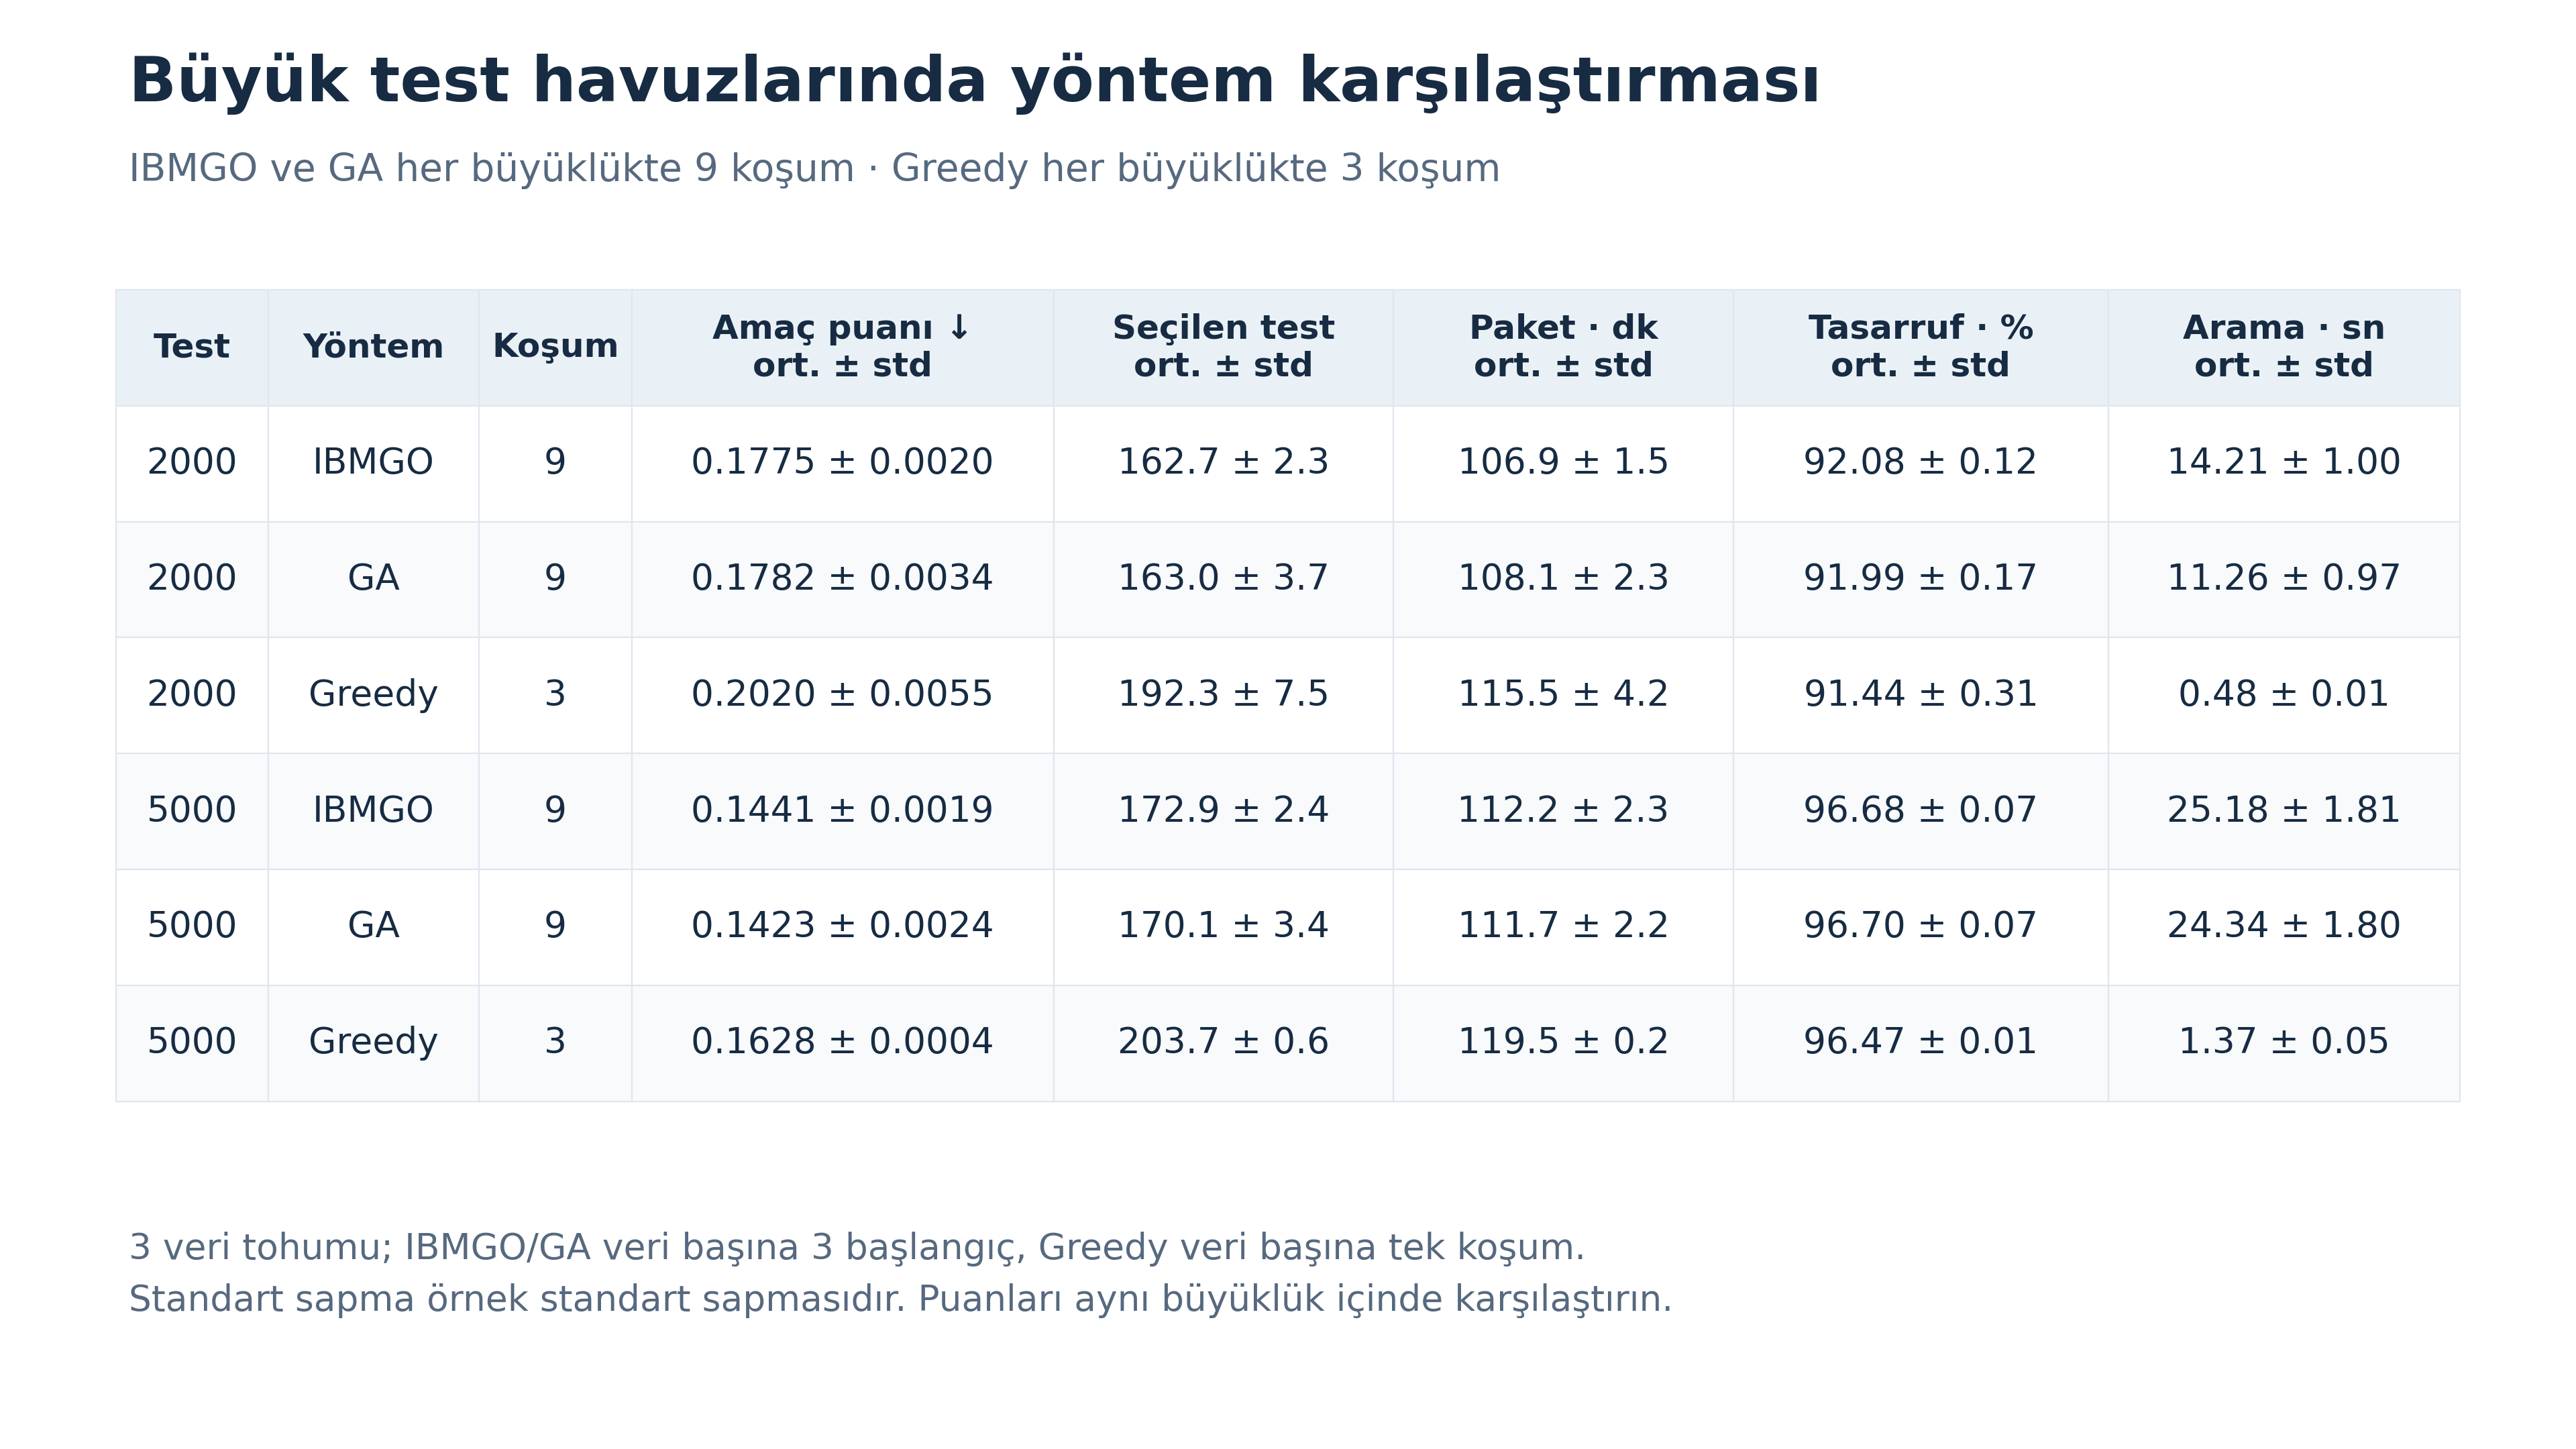

In [6]:
slayt(OLCEK, "01_olcek_ozet.png")

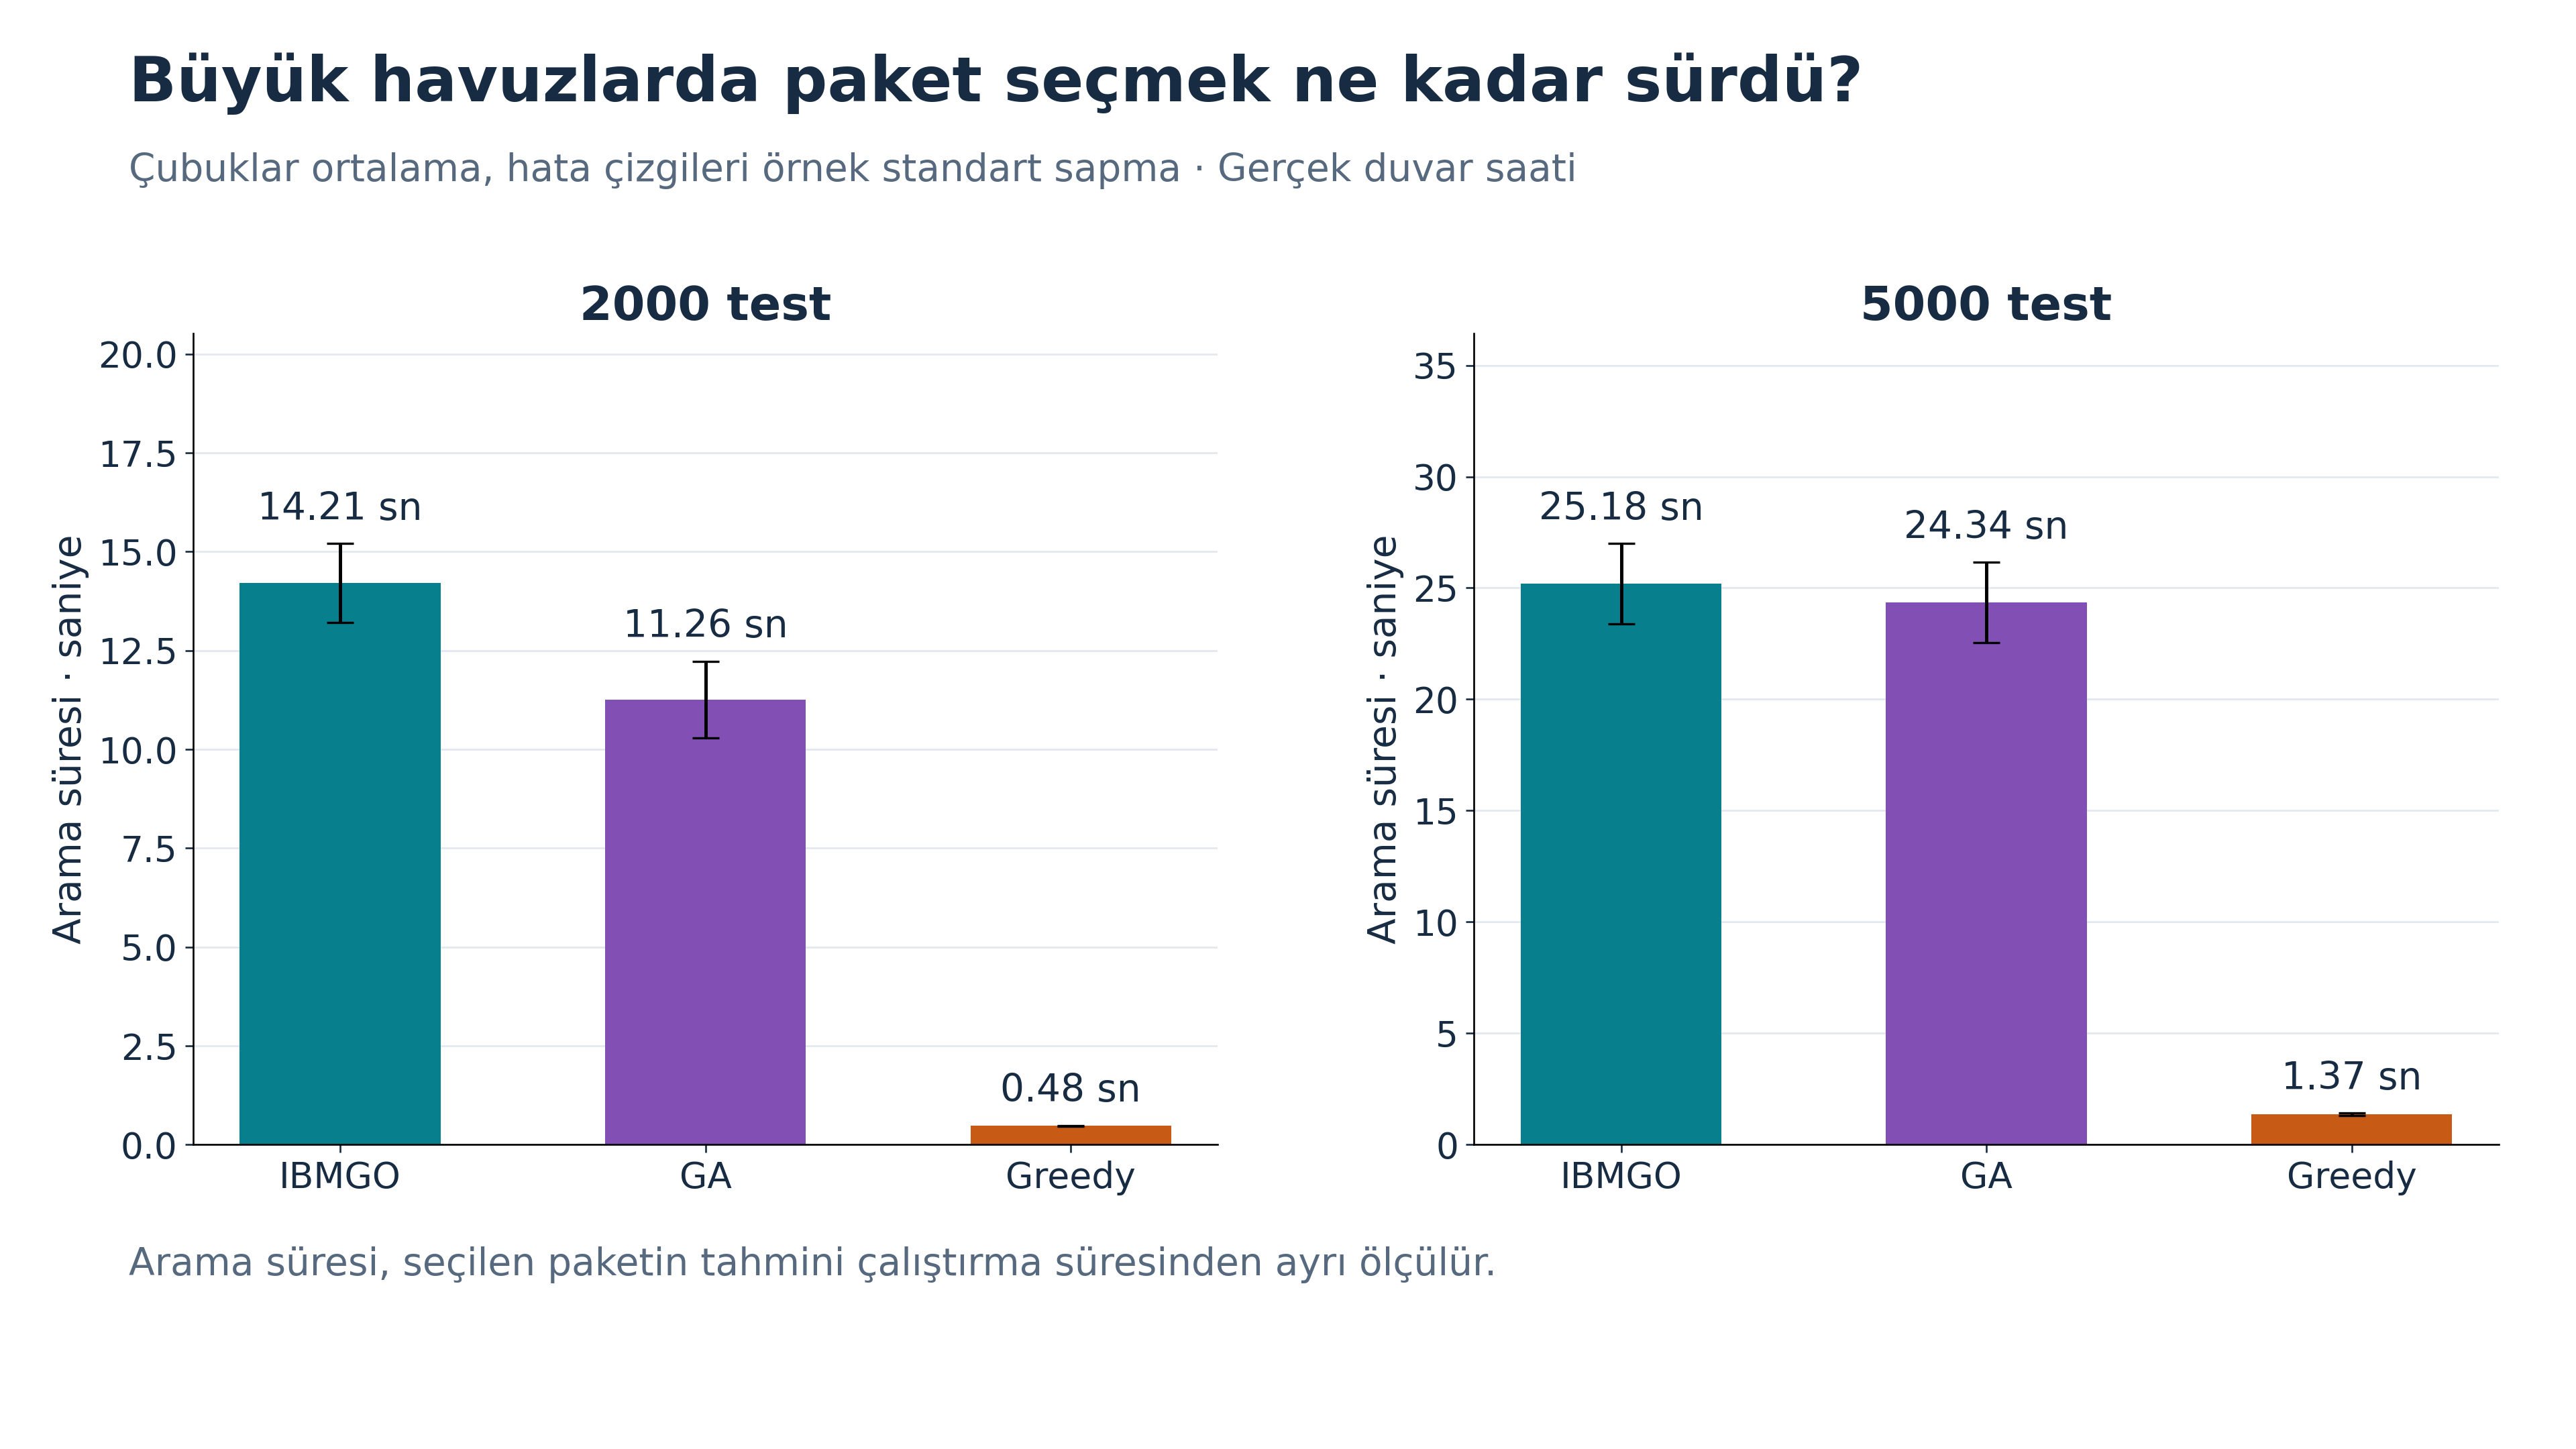

In [7]:
slayt(OLCEK, "02_arama_suresi.png")

### Havuz yapısı ve paketlerin geçerliliği

Hedef sayısı ile hedef başına kapsayan test sayısı birlikte incelenir. Test sayısının artması tek başına zorluğun arttığını göstermez.

In [8]:
try:
    import ipywidgets as w
    gorunumler = [w.Image(value=(OLCEK / "sunum" / ad).read_bytes(),
                         layout=w.Layout(width="100%", max_width="1100px"))
                  for ad in ("03_havuz_yapisi.png", "04_kisit_kontrolleri.png")]
    havuz_sekmeleri = w.Tab(children=gorunumler)
    havuz_sekmeleri.set_title(0, "Veri yapısı")
    havuz_sekmeleri.set_title(1, "Kısıt kontrolleri")
    display(havuz_sekmeleri)
except ImportError:
    slayt(OLCEK, "03_havuz_yapisi.png")
    slayt(OLCEK, "04_kisit_kontrolleri.png")

In [9]:
ozet = pd.read_csv(OLCEK / "olcek_ozet.csv")
for boyut, grup in ozet.groupby("test_sayisi"):
    metin = [f'{r.yontem} amaç puanı {r.fitness_mean:.5f}, arama {r.arama_sn_mean:.2f} sn'
             for _, r in grup.iterrows()]
    display(Markdown(f'**{boyut} test.** ' + '; '.join(metin) + '.'))

**2000 test.** IBMGO amaç puanı 0.17749, arama 14.21 sn; GA amaç puanı 0.17824, arama 11.26 sn; Greedy amaç puanı 0.20202, arama 0.48 sn.

**5000 test.** IBMGO amaç puanı 0.14413, arama 25.18 sn; GA amaç puanı 0.14227, arama 24.34 sn; Greedy amaç puanı 0.16278, arama 1.37 sn.

### Teknik ayrıntılar ve yeniden üretim

Önceki 90 ve yeni 90 koşumun kaynakları kendi klasörlerinde korunur. Birleşik klasör CSV özetleri ve sunum görsellerini içerir. Yeni koşumlar önceki ölçek kayıtlarından alınmadı.

In [10]:
import html
bilgi = '<details><summary>Uyumluluk kontrollerini ve kaynakları aç</summary>'
bilgi += '<ul>' + ''.join('<li>' + html.escape(v) + '</li>' for v in birlesik_manifest['checks']) + '</ul>'
bilgi += '<pre>' + html.escape(json.dumps(birlesik_manifest['sources'], ensure_ascii=False, indent=2)) + '</pre>'
kontroller = pd.read_csv(BIRLESIK / 'kisit_kontrolleri.csv').rename(columns={
    'test_sayisi': 'Test', 'iterasyon': 'İterasyon', 'kosum_sayisi': 'Koşum',
    'gecerli_oran': 'Geçerli oran', 'kritik_kapsam_yuzde_min': 'En düşük kritik kapsam %',
    'genel_kapsam_yuzde_min': 'En düşük genel kapsam %', 'on_kosul_ihlali_max': 'En çok ön koşul ihlali'})
bilgi += kontroller.to_html(index=False, float_format=lambda v: f'{v:.2f}')
bilgi += f'<p>Yeni koşumlar {yeni_manifest["completed"]}/{yeni_manifest["total"]}; durum {yeni_manifest["status"]}.</p></details>'
display(HTML(bilgi))

Test,İterasyon,Koşum,Geçerli oran,En düşük kritik kapsam %,En düşük genel kapsam %,En çok ön koşul ihlali
250,20,15,1.00,100.00,90.19,0
250,50,15,1.00,100.00,90.19,0
250,100,15,1.00,100.00,90.19,0
500,20,15,1.00,100.00,90.00,0
500,50,15,1.00,100.00,90.00,0
500,100,15,1.00,100.00,90.00,0
1000,20,15,1.00,100.00,90.06,0
1000,50,15,1.00,100.00,90.06,0
1000,100,15,1.00,100.00,90.06,0
5000,20,15,1.00,100.00,90.10,0


Yeni 90 koşuma devam etmek için proje klasöründe şu komutu kullanın. Tamamlanan kayıtlar doğrulanıp atlanır.

```powershell
python -B -m kod.deneyler.iterasyon_genisletme --output sonuclar/ek_iterasyon_1000_5000_2026-11-13
```

Birleşik rapor ve PNG dosyaları `python -B -m kod.raporlama.iterasyon_birlesik` ile yeniden üretilir.